# Product Recommendation Engine Workbook

This notebook is designed for beginners. It builds a product recommendation
engine for a generic online shop using customer-product interaction data.

The workflow follows the recommendation-engine ideas from the product
recommendation page: browsing, clicks, purchases, ratings/reviews, product
information.

In this workbook you will:

1. Load sample CSV files.
2. Convert customer events into an implicit-feedback user-item matrix.
3. Apply BM25 re-weighting.
4. Train an Alternating Least Squares matrix-factorization model.
5. Use Optuna to search hyperparameters.
6. Save recommendation and evaluation outputs.

## Before You Start

If packages are missing, open a terminal in this folder and run:

```bash
pip install -r requirements.txt
```

Then restart the notebook kernel and run the cells again.

## Cell 1: Import Packages

Run this cell first. It imports standard analysis packages and the local
helper code in the `code/` folder.

The notebook can run a small educational ALS fallback if `implicit` is not
installed, but install the requirements for the intended BM25, ALS, and
Optuna workflow.

In [1]:
from pathlib import Path
import importlib.util
import os
import sys

import numpy as np
import pandas as pd
from IPython.display import display

BASE_DIR = Path.cwd()
CODE_DIR = BASE_DIR / "code"
OUTPUT_DIR = BASE_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
MPL_CACHE_DIR = OUTPUT_DIR / ".matplotlib"
MPL_CACHE_DIR.mkdir(exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPL_CACHE_DIR))

import matplotlib.pyplot as plt

if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))

from product_recommender import (
    apply_bm25_weighting,
    build_user_item_matrix,
    evaluate_recommendations,
    fit_als_model,
    get_recommendations_for_user,
    get_similar_items,
    load_sample_data,
    prepare_interaction_strengths,
    run_optuna_search,
    train_test_split_by_user,
)

missing_packages = [
    package_name
    for package_name in ["implicit", "optuna"]
    if importlib.util.find_spec(package_name) is None
]

if missing_packages:
    print("Missing optional/required modelling packages:", missing_packages)
    print("Run this in a terminal opened in this folder: pip install -r requirements.txt")
else:
    print("All modelling packages are available.")

All modelling packages are available.


## Cell 2: File Locations and User Settings

Basic users usually only need to edit the settings below.

`N_OPTUNA_TRIALS` controls how many hyperparameter combinations Optuna
tests. Increase it for a deeper search, or reduce it if the notebook is
taking too long.

In [2]:
INTERACTIONS_PATH = BASE_DIR / "customer_product_interactions.csv"
CATALOG_PATH = BASE_DIR / "product_catalog.csv"
CUSTOMER_SEGMENTS_PATH = BASE_DIR / "customer_segments.csv"

TOP_N_RECOMMENDATIONS = 10
N_OPTUNA_TRIALS = 20
RANDOM_STATE = 42

DEFAULT_PARAMS = {
    "factors": 32,
    "regularization": 0.05,
    "alpha": 40.0,
    "iterations": 12,
    "bm25_k1": 100.0,
    "bm25_b": 0.8,
}

print("Base folder:", BASE_DIR)
print("Outputs will be saved to:", OUTPUT_DIR)

Base folder: /home/runner/work/Product-Recommendation-Engine/Product-Recommendation-Engine
Outputs will be saved to: /home/runner/work/Product-Recommendation-Engine/Product-Recommendation-Engine/outputs


## Cell 3: Load the Sample CSV Files

The main modelling file is `customer_product_interactions.csv`.

Each row is one customer-product event, such as a view, click, basket add,
purchase, or review. Matrix factorization uses the interaction file. The
product catalog is used to make recommendation outputs readable.

In [3]:
interactions, catalog = load_sample_data(BASE_DIR)
customer_segments = pd.read_csv(CUSTOMER_SEGMENTS_PATH)

print("Interaction rows:", len(interactions))
print("Products:", catalog["item_id"].nunique())
print("Customers:", interactions["user_id"].nunique())

display(interactions.head())
display(catalog.head())
display(customer_segments.head())

Interaction rows: 5298
Products: 70
Customers: 140


,user_id,item_id,event_type,event_strength,quantity,unit_price,interaction_datetime,session_id
0,CUST042,ITEM044,view,1.0,1,34.12,2026-01-01T09:10:00,SESSION00714
1,CUST079,ITEM052,view,1.0,1,12.15,2026-01-01T09:57:00,SESSION01355
2,CUST079,ITEM052,add_to_cart,4.0,1,12.15,2026-01-01T10:00:00,SESSION01355
3,CUST129,ITEM035,view,1.0,1,145.75,2026-01-01T10:10:00,SESSION02171
4,CUST129,ITEM035,add_to_cart,4.0,1,145.75,2026-01-01T10:13:00,SESSION02171


,item_id,product_name,category,price,margin_band,average_rating,stock_status,product_age_days
0,ITEM001,Stainless Saucepan,Kitchen,103.12,high,3.7,in_stock,503
1,ITEM002,Bamboo Chopping Board,Kitchen,68.74,medium,3.9,in_stock,206
2,ITEM003,Ceramic Dinner Plate Set,Kitchen,24.74,medium,4.8,in_stock,433
3,ITEM004,Glass Food Storage Set,Kitchen,38.57,medium,4.6,in_stock,269
4,ITEM005,Compact Air Fryer,Kitchen,99.04,high,4.3,in_stock,90


,user_id,customer_segment,preferred_price_band,loyalty_tier
0,CUST001,active_lifestyle,mid_range,frequent
1,CUST002,pet_household,mid_range,frequent
2,CUST003,active_lifestyle,premium,standard
3,CUST004,outdoor_planner,mid_range,frequent
4,CUST005,pet_household,budget,new


## Cell 4: Build the User-Item Matrix

Recommendation models need a matrix where:

- rows are customers
- columns are products
- values represent confidence that a customer is interested in a product

The notebook first converts event types into strengths. For example, a
purchase is stronger evidence than a product view. Then it aggregates all
events for each customer-product pair.

In [4]:
prepared_interactions = prepare_interaction_strengths(interactions)
user_item_matrix, aggregated_interactions, mappings = build_user_item_matrix(
    prepared_interactions
)

aggregated_interactions.to_csv(
    OUTPUT_DIR / "aggregated_user_item_interactions.csv", index=False
)

print("User-item matrix shape:", user_item_matrix.shape)
print("Non-zero user-item pairs:", user_item_matrix.nnz)
print("Matrix sparsity:", round(1 - user_item_matrix.nnz / np.prod(user_item_matrix.shape), 4))

display(aggregated_interactions.head())

User-item matrix shape: (140, 70)
Non-zero user-item pairs: 2343
Matrix sparsity: 0.7609


,user_id,item_id,interaction_strength,event_count,last_event_time,matrix_value
0,CUST001,ITEM006,3.000000,2,2026-01-08T18:26:00,1.386294
1,CUST001,ITEM019,20.856406,4,2026-01-18T17:46:00,3.084494
2,CUST001,ITEM020,7.000000,3,2026-04-05T21:24:00,2.079442
3,CUST001,ITEM024,20.856406,4,2026-01-11T18:40:00,3.084494
4,CUST001,ITEM029,3.000000,2,2026-03-19T10:55:00,1.386294


## Cell 5: Train/Test Split

To evaluate the recommender, we hide a few known customer-product
interactions from the model. After training, we check whether the model
recommends those hidden products.

In [5]:
train_matrix, test_matrix = train_test_split_by_user(
    user_item_matrix,
    test_fraction=0.2,
    min_items_for_test=4,
    random_state=RANDOM_STATE,
)

print("Training interactions:", train_matrix.nnz)
print("Held-out test interactions:", test_matrix.nnz)

Training interactions: 1871
Held-out test interactions: 472


## Cell 6: Baseline BM25 plus ALS Model

BM25 re-weighting reduces the impact of products that almost everyone
interacts with and customers who interact with many products.

ALS then decomposes the sparse customer-product matrix into two lower
dimensional matrices: one for customers and one for products. The algorithm
alternates between fixing one matrix and optimizing the other, which makes
it practical for sparse recommendation data.

In [6]:
weighted_train_default = apply_bm25_weighting(
    train_matrix,
    k1=DEFAULT_PARAMS["bm25_k1"],
    b=DEFAULT_PARAMS["bm25_b"],
)

baseline_model = fit_als_model(
    weighted_train_default,
    factors=DEFAULT_PARAMS["factors"],
    regularization=DEFAULT_PARAMS["regularization"],
    alpha=DEFAULT_PARAMS["alpha"],
    iterations=DEFAULT_PARAMS["iterations"],
    random_state=RANDOM_STATE,
    show_progress=False,
)

print("Model source:", getattr(baseline_model, "source_library", "implicit"))
baseline_metrics, baseline_user_metrics = evaluate_recommendations(
    baseline_model,
    train_matrix,
    test_matrix,
    k=TOP_N_RECOMMENDATIONS,
)
display(pd.DataFrame([baseline_metrics]))

Model source: implicit


/opt/hostedtoolcache/Python/3.12.16/x64/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/opt/hostedtoolcache/Python/3.12.16/x64/lib/python3.12/site-packages/implicit/cpu/als.py:96: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


,evaluated_users,mean_precision_at_k,mean_recall_at_k,mean_hit_rate_at_k
0,140,0.070714,0.215357,0.571429


## Cell 7: Hyperparameter Search with Optuna

Optuna tests different model settings and keeps the settings that perform
best on the held-out data.

This search tunes:

- number of ALS latent factors
- regularization
- alpha confidence scaling
- ALS iterations
- BM25 `k1`
- BM25 `b`

In [7]:
try:
    best_params, trials_df = run_optuna_search(
        train_matrix,
        test_matrix,
        n_trials=N_OPTUNA_TRIALS,
        k=TOP_N_RECOMMENDATIONS,
        random_state=RANDOM_STATE,
    )
    search_used_optuna = True
    trials_df.to_csv(OUTPUT_DIR / "als_optuna_trials.csv", index=False)
    print("Optuna search finished.")
except ImportError as exc:
    print(exc)
    print("Using default parameters so the rest of the notebook can run.")
    best_params = DEFAULT_PARAMS.copy()
    trials_df = pd.DataFrame()
    search_used_optuna = False

pd.DataFrame([best_params]).to_csv(OUTPUT_DIR / "best_als_parameters.csv", index=False)
print("Selected parameters:")
display(pd.DataFrame([best_params]))

if not trials_df.empty:
    display(trials_df.sort_values("value", ascending=False).head())

[I 2026-11-08 12:39:16,806] A new study created in memory with name: no-name-4d2d70d2-f560-43ba-a6ed-a4b28c18f495


[I 2026-11-08 12:39:16,835] Trial 0 finished with value: 0.1936904761904762 and parameters: {'factors': 24, 'regularization': 0.0024345423962016913, 'alpha': 5.873671345397129, 'iterations': 18, 'bm25_k1': 116.1784018789134, 'bm25_b': 0.7664580622368364}. Best is trial 0 with value: 0.1936904761904762.


[I 2026-11-08 12:39:16,855] Trial 1 finished with value: 0.1872619047619047 and parameters: {'factors': 24, 'regularization': 0.002846526357761094, 'alpha': 11.622891098010612, 'iterations': 13, 'bm25_k1': 89.11120298273852, 'bm25_b': 0.43298331215843355}. Best is trial 0 with value: 0.1936904761904762.


[I 2026-11-08 12:39:16,875] Trial 2 finished with value: 0.23857142857142857 and parameters: {'factors': 16, 'regularization': 0.08810003129071789, 'alpha': 8.69763534223623, 'iterations': 13, 'bm25_k1': 114.7863310179268, 'bm25_b': 0.2371603301759982}. Best is trial 2 with value: 0.23857142857142857.


[I 2026-11-08 12:39:16,961] Trial 3 finished with value: 0.2030952380952381 and parameters: {'factors': 64, 'regularization': 0.10057690178153984, 'alpha': 11.634869883368138, 'iterations': 6, 'bm25_k1': 129.47728424194509, 'bm25_b': 0.5521219949916811}. Best is trial 2 with value: 0.23857142857142857.


[I 2026-11-08 12:39:17,064] Trial 4 finished with value: 0.18559523809523806 and parameters: {'factors': 48, 'regularization': 0.043767126303409544, 'alpha': 11.866087319371896, 'iterations': 13, 'bm25_k1': 107.47364469492474, 'bm25_b': 0.3478835644204217}. Best is trial 2 with value: 0.23857142857142857.


... (14 outputs left out)

[I 2026-11-08 12:39:17,701] Trial 19 finished with value: 0.2351190476190476 and parameters: {'factors': 16, 'regularization': 0.0054174573315986935, 'alpha': 51.460618085951666, 'iterations': 19, 'bm25_k1': 171.3903997184335, 'bm25_b': 0.6781015633531106}. Best is trial 13 with value: 0.2714285714285714.


Optuna search finished.
Selected parameters:


,factors,regularization,alpha,iterations,bm25_k1,bm25_b
0,16,0.005119,30.799905,11,135.958166,0.425137


,number,value,datetime_start,datetime_complete,duration,params_alpha,params_bm25_b,params_bm25_k1,params_factors,params_iterations,params_regularization,system_attrs_tpe:relative_params:0,state
13,13,0.271429,2026-11-08 12:39:17.541789,2026-11-08 12:39:17.561871,0 days 00:00:00.020082,30.799905,0.425137,135.958166,16,11,0.005119,"{""alpha"": 30.799904711456957, ""bm25_b"": 0.4251...",COMPLETE
8,8,0.266310,2026-11-08 12:39:17.119339,2026-11-08 12:39:17.139438,0 days 00:00:00.020099,37.801008,0.577772,161.954039,16,15,0.006390,NaN,COMPLETE
15,15,0.259643,2026-11-08 12:39:17.584043,2026-11-08 12:39:17.608281,0 days 00:00:00.024238,29.679507,0.645874,114.627081,16,15,0.002590,"{""alpha"": 29.679506587566983, ""bm25_b"": 0.6458...",COMPLETE
16,16,0.242143,2026-11-08 12:39:17.608687,2026-11-08 12:39:17.628851,0 days 00:00:00.020164,24.501429,0.262281,94.823666,16,9,0.011702,"{""alpha"": 24.501428637074614, ""bm25_b"": 0.2622...",COMPLETE
12,12,0.240119,2026-11-08 12:39:17.521040,2026-11-08 12:39:17.541400,0 days 00:00:00.020360,46.925509,0.476462,178.904006,16,13,0.100523,"{""alpha"": 46.925508571533854, ""bm25_b"": 0.4764...",COMPLETE


## Cell 8: Train the Final ALS Model

This cell retrains ALS using the selected hyperparameters. If Optuna ran,
these are the best parameters found during the search. Otherwise, they are
the default teaching parameters.

In [8]:
weighted_train = apply_bm25_weighting(
    train_matrix,
    k1=float(best_params["bm25_k1"]),
    b=float(best_params["bm25_b"]),
)

final_model = fit_als_model(
    weighted_train,
    factors=int(best_params["factors"]),
    regularization=float(best_params["regularization"]),
    alpha=float(best_params["alpha"]),
    iterations=int(best_params["iterations"]),
    random_state=RANDOM_STATE,
    show_progress=False,
)

final_metrics, user_level_metrics = evaluate_recommendations(
    final_model,
    train_matrix,
    test_matrix,
    k=TOP_N_RECOMMENDATIONS,
)

pd.DataFrame([final_metrics]).to_csv(OUTPUT_DIR / "als_evaluation_metrics.csv", index=False)
user_level_metrics.to_csv(OUTPUT_DIR / "als_user_level_metrics.csv", index=False)

print("Final model source:", getattr(final_model, "source_library", "implicit"))
display(pd.DataFrame([final_metrics]))

Final model source: implicit


,evaluated_users,mean_precision_at_k,mean_recall_at_k,mean_hit_rate_at_k
0,140,0.092857,0.271429,0.657143


## Cell 9: Create Product Recommendations

This cell creates top product recommendations for a few sample customers.
The model filters out products the customer has already interacted with in
the training data.

In [9]:
sample_users = list(mappings.user_to_index.keys())[:5]

recommendation_tables = []
for user_id in sample_users:
    user_recommendations = get_recommendations_for_user(
        final_model,
        user_id,
        mappings,
        train_matrix,
        catalog,
        n_recommendations=TOP_N_RECOMMENDATIONS,
    )
    user_recommendations.insert(0, "user_id", user_id)
    recommendation_tables.append(user_recommendations)

all_recommendations = pd.concat(recommendation_tables, ignore_index=True)
all_recommendations.to_csv(
    OUTPUT_DIR / "sample_user_recommendations.csv", index=False
)

display(all_recommendations.head(15))

,user_id,rank,item_id,recommendation_score,product_name,category,price,margin_band,average_rating,stock_status,product_age_days
0,CUST001,1,ITEM055,1.324662,Waterproof Phone Pouch,Outdoor,109.73,high,4.7,in_stock,287
1,CUST001,2,ITEM034,1.063064,USB-C Hub,Office Tech,67.31,medium,4.0,in_stock,287
2,CUST001,3,ITEM008,0.999076,Reusable Baking Mat,Kitchen,48.78,medium,3.8,in_stock,378
3,CUST001,4,ITEM057,0.945943,Garden Gloves,Outdoor,28.36,medium,3.6,in_stock,81
4,CUST001,5,ITEM043,0.938164,Foam Roller,Fitness,117.52,high,3.8,in_stock,448
5,CUST001,6,ITEM011,0.864002,Cotton Towel Set,Home,7.35,low,4.1,in_stock,277
6,CUST001,7,ITEM070,0.804765,Pet Blanket,Pet Supplies,63.53,medium,4.3,in_stock,456
7,CUST001,8,ITEM007,0.766162,Insulated Lunch Box,Kitchen,35.79,medium,4.2,in_stock,248
8,CUST001,9,ITEM001,0.710829,Stainless Saucepan,Kitchen,103.12,high,3.7,in_stock,503
9,CUST001,10,ITEM018,0.704765,Door Mat,Home,85.18,high,4.7,in_stock,198


## Cell 10: Find Similar Products

ALS learns a vector for each product. Products with similar vectors are
products that tend to be liked by similar customers.

In [10]:
sample_item_id = catalog["item_id"].iloc[0]
similar_items = get_similar_items(
    final_model,
    sample_item_id,
    mappings,
    catalog,
    n_items=10,
)
similar_items.to_csv(OUTPUT_DIR / "sample_similar_items.csv", index=False)

print("Similar products for:", sample_item_id)
display(similar_items)

Similar products for: ITEM001


,rank,item_id,similarity_score,product_name,category,price,margin_band,average_rating,stock_status,product_age_days
0,1,ITEM001,1.000000,Stainless Saucepan,Kitchen,103.12,high,3.7,in_stock,503
1,2,ITEM035,0.406125,Noise Reducing Headset,Office Tech,145.75,high,4.1,in_stock,279
2,3,ITEM006,0.400030,Digital Kitchen Scale,Kitchen,79.43,high,4.1,in_stock,527
3,4,ITEM044,0.344246,Adjustable Dumbbell,Fitness,34.12,medium,4.0,limited_stock,480
4,5,ITEM013,0.338068,Storage Basket,Home,49.13,medium,4.4,in_stock,145
5,6,ITEM038,0.317946,Cable Management Kit,Office Tech,126.85,high,3.9,in_stock,118
6,7,ITEM012,0.300919,Soft Throw Blanket,Home,21.85,medium,4.0,in_stock,531
7,8,ITEM017,0.261112,Laundry Hamper,Home,48.91,medium,4.6,in_stock,332
8,9,ITEM011,0.257654,Cotton Towel Set,Home,7.35,low,4.1,in_stock,277
9,10,ITEM028,0.250081,Sleep Mask,Personal Care,33.81,medium,3.6,in_stock,51


## Cell 11: Visual Summary

This cell saves two simple charts:

- category mix of the sample recommendations
- Optuna trial history, if Optuna was installed and used

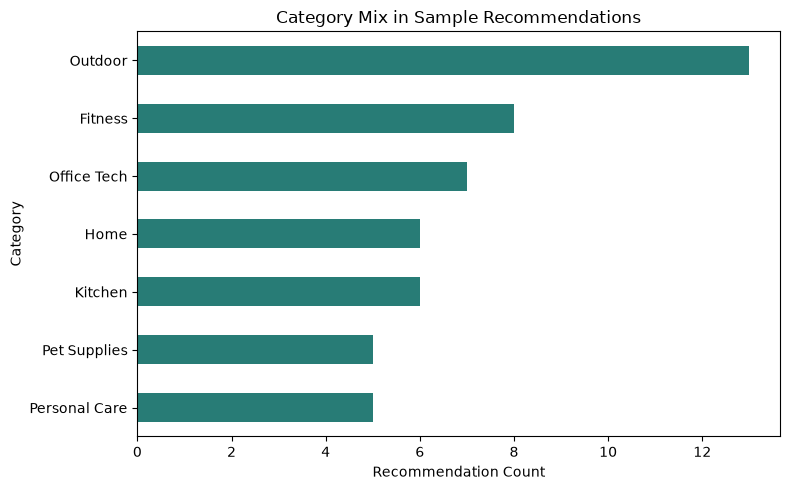

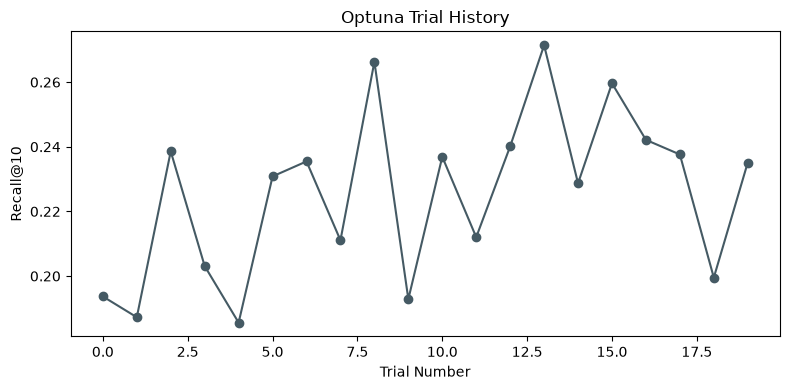

In [11]:
category_counts = all_recommendations["category"].value_counts().sort_values()

plt.figure(figsize=(8, 5))
category_counts.plot(kind="barh", color="#287c76")
plt.title("Category Mix in Sample Recommendations")
plt.xlabel("Recommendation Count")
plt.ylabel("Category")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "recommendation_category_mix.png", dpi=150)
plt.show()

if not trials_df.empty and "value" in trials_df.columns:
    plt.figure(figsize=(8, 4))
    plt.plot(trials_df["number"], trials_df["value"], marker="o", color="#455a64")
    plt.title("Optuna Trial History")
    plt.xlabel("Trial Number")
    plt.ylabel(f"Recall@{TOP_N_RECOMMENDATIONS}")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "optuna_trial_history.png", dpi=150)
    plt.show()
else:
    print("Optuna trial chart skipped because Optuna did not run.")

## Cell 12: What to Try Next

After you understand the sample notebook, try these changes:

- Increase `N_OPTUNA_TRIALS` for a more thorough search.
- Change event weights in `code/product_recommender/data.py`.
- Add more interaction rows to `customer_product_interactions.csv`.
- Compare recommendations for customers from different segments.
- Add cold-start logic for new products with no interactions.

The output files are saved in the `outputs/` folder.